## MCF-7 and *F. nucleatum* Community - Knock Out

In [63]:
import micom
import osqp
import pandas as pd
import numpy as np
import pickle
import cobra
from micom import load_pickle
from micom.media import minimal_medium
from micom.workflows import workflow
from micom import Community
from time import time
from cobra.flux_analysis import (single_gene_deletion, single_reaction_deletion)
from pathlib import Path
from cobra.io import read_sbml_model, write_sbml_model
import seaborn as sns
import matplotlib.pyplot as plt

### Create community

#### Community with *F. nucleatum*

In [2]:
TyF = {'id': ['CanA', 'CanB', 'CanC','Fusobacterium'],
    'file': ["A_1.xml", 'B_1.xml','C_1.xml',"F_1.xml"],
     'abundance': [0.04885,0.1955,0.2265,0.50]
    }

df_TyF = pd.DataFrame(data=TyF)
df_TyF

,id,file,abundance
0,CanA,A_1.xml,0.04885
1,CanB,B_1.xml,0.19550
2,CanC,C_1.xml,0.22650
3,Fusobacterium,F_1.xml,0.50000


In [3]:
TyF = micom.Community (df_TyF, solver = "osqp")
print("build a community with a total of {} reactions.".format(len(TyF.reactions)))

Output()

build a community with a total of 4120 reactions.


In [4]:
# add medium
TyF.medium =  {
'EX_ala_L_m':0.7,
'EX_arg_L_m':0.5,  
'EX_asn_L_m':0.7,
'EX_asp_L_m':0.7,
'EX_ca2_m':0.5,
'EX_chol_m':0.7,
'EX_cl_m':0.5, 
'EX_cobalt2_m':0.5, 
'EX_cu2_m':0.5, 
'EX_cys_L_m':0.7,
'EX_fe2_m':0.5, 
'EX_fe3_m':0.5, 
'EX_gal_m':0.01,  
'EX_gln_L_m':0.7,
'EX_his_L_m':0.7,
'EX_ile_L_m':0.7,
'EX_inost_m':0.7,
'EX_k_m':0.5, 
'EX_leu_L_m':0.7,
'EX_lys_L_m':0.5,  
'EX_met_L_m':0.7,
'EX_mg2_m':0.5,  
'EX_mn2_m':0.5,  
'EX_nac_m':0.5,  
'EX_o2_m':0.7,
'EX_h2o_m':0.7,
'EX_phe_L_m':0.5, 
'EX_pi_m':0.5, 
'EX_pnto_R_m':0.5,
'EX_pro_L_m':0.5, 
'EX_ser_L_m':0.7,
'EX_so4_m':0.5, 
'EX_thr_L_m':0.7,
'EX_trp_L_m':0.5, 
'EX_tyr_L_m':0.5,
'EX_val_L_m':0.5,
'EX_zn2_m':0.5, 
'EX_adocbl_m':0.7,
'EX_anth_m':0.7,
'EX_ascb_L_m':0.7,
'EX_btn_m':0.7,
'EX_fol_m':0.7,
'EX_glc_D_m':0.7,
'EX_glu_L_m':0.7,
'EX_gly_m':0.7,
'EX_gthrd_m':0.7,
'EX_na1_m':0.7,
'EX_ncam_m':0.7,
'EX_pydxn_m':0.7,
'EX_ribflv_m':0.7,
'EX_thm_m':0.7
}

In [5]:
#optimize community
sol_TyF = TyF.cooperative_tradeoff(fraction = 0.6, fluxes =True, pfba = True)
sol_TyF

,abundance,growth_rate,reactions,metabolites
compartments,,,,
CanA,0.050317,0.010434,1126,982
CanB,0.201370,0.041760,742,616
CanC,0.233301,0.048382,1032,807
Fusobacterium,0.515013,0.117332,1029,935
medium,NaN,NaN,191,191


#### Community without *F. nucleatum*

In [8]:
Tumor = {'id': ['CanA', 'CanB', 'CanC','Fuso'],
    'file': ["A_1.xml", 'B_1.xml','C_1.xml',"F_1.xml"],
     'abundance': [0.04885,0.1955,0.2265,0] #the abundance for Fusobacterium will be 0.
    }

df_T = pd.DataFrame(data=Tumor)
df_T

,id,file,abundance
0,CanA,A_1.xml,0.04885
1,CanB,B_1.xml,0.19550
2,CanC,C_1.xml,0.22650
3,Fuso,F_1.xml,0.00000


In [9]:
Tumor = micom.Community (df_T, solver = "osqp")
print("build a community with a total of {} reactions.".format(len(Tumor.reactions)))

Output()

build a community with a total of 3017 reactions.


In [10]:
## Add medium
Tumor.medium =  {
'EX_ala_L_m':0.7,
'EX_arg_L_m':0.5,  
'EX_asn_L_m':0.7,
'EX_asp_L_m':0.7,
'EX_ca2_m':0.5,
'EX_chol_m':0.7,
'EX_cl_m':0.5, 
'EX_cobalt2_m':0.5, 
'EX_cu2_m':0.5, 
'EX_cys_L_m':0.7,
'EX_fe2_m':0.5, 
'EX_fe3_m':0.5, 
'EX_gal_m':0.01,  
'EX_gln_L_m':0.7,
'EX_his_L_m':0.7,
'EX_ile_L_m':0.7,
'EX_inost_m':0.7,
'EX_k_m':0.5, 
'EX_leu_L_m':0.7,
'EX_lys_L_m':0.5,  
'EX_met_L_m':0.7,
'EX_mg2_m':0.5,  
'EX_mn2_m':0.5,  
'EX_nac_m':0.5,  
'EX_o2_m':0.7,
'EX_h2o_m':0.7,
'EX_phe_L_m':0.5, 
'EX_pi_m':0.5, 
'EX_pnto_R_m':0.5,
'EX_pro_L_m':0.5, 
'EX_ser_L_m':0.7,
'EX_so4_m':0.5, 
'EX_thr_L_m':0.7,
'EX_trp_L_m':0.5, 
'EX_tyr_L_m':0.5,
'EX_val_L_m':0.5,
'EX_zn2_m':0.5, 
'EX_adocbl_m':0.7,
'EX_anth_m':0.7,
'EX_ascb_L_m':0.7,
'EX_btn_m':0.7,
'EX_fol_m':0.7,
'EX_glc_D_m':0.7,
'EX_glu_L_m':0.7,
'EX_gly_m':0.7,
'EX_gthrd_m':0.7,
'EX_na1_m':0.7,
'EX_ncam_m':0.7,
'EX_pydxn_m':0.7,
'EX_ribflv_m':0.7,
'EX_thm_m':0.7
}

In [11]:
#Optimize community
sol_Tumor = Tumor.cooperative_tradeoff(fraction = 0.6, fluxes =True, pfba = True)
sol_Tumor 

,abundance,growth_rate,reactions,metabolites
compartments,,,,
CanA,0.103749,0.005209,1126,982
CanB,0.415207,0.020849,742,616
CanC,0.481045,0.026206,1032,807
medium,NaN,NaN,117,117


### Analysis of essentiality by K.O. of reactions

#### Community with *F. nucleatum*

In [7]:
len(TyF.reactions) # Count reactions within the community to make the K.O.

4120

In [ ]:
deletion=single_reaction_deletion(TyF, TyF.reactions [:4120])

In [ ]:
deletion.to_csv("KO_community_TyF.csv") #save to csv for analizing

#### Community without *F. nucleatum*

In [12]:
len (Tumor.reactions)

3017

In [ ]:
deletion_t=single_reaction_deletion(Tumor, Tumor.reactions [:3017])

In [ ]:
deletion_t.to_csv("KO_community_Tumor.csv")

### K.O. of essencial reactions of Community

In [ ]:
A = cobra.io.read_sbml_model('A_1.xml')
B = cobra.io.read_sbml_model('B_1.xml')
C = cobra.io.read_sbml_model('C_1.xml')

#### K.O. reactions of Galactose

In [42]:
A.reactions.EX_gal_e.lower_bound = 0
A.reactions.EX_gal_e.upper_bound = 0

B.reactions.EX_gal_e.lower_bound = 0
B.reactions.EX_gal_e.upper_bound = 0

C.reactions.EX_gal_e.lower_bound = 0
C.reactions.EX_gal_e.upper_bound = 0

#### K.O. reactions of Glutamine

In [31]:
A.reactions.EX_gln_L_e.lower_bound = 0
A.reactions.EX_gln_L_e.upper_bound = 0

B.reactions.EX_gln_L_e.lower_bound = 0
B.reactions.EX_gln_L_e.upper_bound = 0

C.reactions.EX_gln_L_e.lower_bound = 0
C.reactions.EX_gln_L_e.upper_bound = 0

In [43]:
write_sbml_model(A, "A_2.xml")
write_sbml_model(B, "B_2.xml")
write_sbml_model(C, "C_2.xml")

#### Analizing the new dynamic of fluxes

In [46]:
TyF_KO = {'id': ['CanA', 'CanB', 'CanC','Fusobacterium'],
    'file': ["A_2.xml", "B_2.xml", "C_2.xml", "F_1.xml"],
     'abundance': [0.04885,0.1955,0.2265,0.50]
    }

df_TyF_KO = pd.DataFrame(data=TyF_KO)
df_TyF_KO

,id,file,abundance
0,CanA,A_2.xml,0.04885
1,CanB,B_2.xml,0.19550
2,CanC,C_2.xml,0.22650
3,Fusobacterium,F_1.xml,0.50000


In [47]:
TyF_KO = micom.Community (df_TyF_KO, solver = "osqp")
print("build a community with a total of {} reactions.".format(len(TyF_KO.reactions)))

Building ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:02:15

build a community with a total of 4120 reactions.


In [53]:
## Add medium
TyF_KO.medium =  {
'EX_ala_L_m':0.7,
'EX_arg_L_m':0.5,  
'EX_asn_L_m':0.7,
'EX_asp_L_m':0.7,
'EX_ca2_m':0.5,
'EX_chol_m':0.7,
'EX_cl_m':0.5, 
'EX_cobalt2_m':0.5, 
'EX_cu2_m':0.5, 
'EX_cys_L_m':0.7,
'EX_fe2_m':0.5, 
'EX_fe3_m':0.5, 
'EX_gal_m':0.01,  
'EX_gln_L_m':0.7,
'EX_his_L_m':0.7,
'EX_ile_L_m':0.7,
'EX_inost_m':0.7,
'EX_k_m':0.5, 
'EX_leu_L_m':0.7,
'EX_lys_L_m':0.5,  
'EX_met_L_m':0.7,
'EX_mg2_m':0.5,  
'EX_mn2_m':0.5,  
'EX_nac_m':0.5,  
'EX_o2_m':0.7,
'EX_h2o_m':0.7,
'EX_phe_L_m':0.5, 
'EX_pi_m':0.5, 
'EX_pnto_R_m':0.5,
'EX_pro_L_m':0.5, 
'EX_ser_L_m':0.7,
'EX_so4_m':0.5, 
'EX_thr_L_m':0.7,
'EX_trp_L_m':0.5, 
'EX_tyr_L_m':0.5,
'EX_val_L_m':0.5,
'EX_zn2_m':0.5, 
'EX_adocbl_m':0.7,
'EX_anth_m':0.7,
'EX_ascb_L_m':0.7,
'EX_btn_m':0.7,
'EX_fol_m':0.7,
'EX_glc_D_m':0.7,
'EX_glu_L_m':0.7,
'EX_gly_m':0.7,
'EX_gthrd_m':0.7,
'EX_na1_m':0.7,
'EX_ncam_m':0.7,
'EX_pydxn_m':0.7,
'EX_ribflv_m':0.7,
'EX_thm_m':0.7
}

In [54]:
sol_TyF_KO = TyF_KO.cooperative_tradeoff(fraction = 0.6, fluxes =True, pfba = True)
sol_TyF_KO

,abundance,growth_rate,reactions,metabolites
compartments,,,,
CanA,0.050317,0.009927,1126,982
CanB,0.201370,0.039732,742,616
CanC,0.233301,0.046031,1032,807
Fusobacterium,0.515013,0.119258,1029,935
medium,NaN,NaN,191,191


In [55]:
fluxesTyF_KO = sol_TyF_KO.fluxes

In [56]:
fluxesTyF_KO

reaction,10FTHF5GLUtl,10FTHF5GLUtm,10FTHF6GLUtl,10FTHF6GLUtm,10FTHF7GLUtl,10FTHF7GLUtm,10FTHFtl,10FTHFtm,15DAPt,1PPDCRp,...,r2503,r2513,r2521,r2537,r2539,rtranscription,sink_citr_LPAREN_c_RPAREN_,sink_dmbzid,sink_s,xmpt
compartment,,,,,,,,,,,,,,,,,,,,,
CanA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,...,NaN,-0.0,0.0,-0.0,NaN,NaN,NaN,NaN,NaN,0.000457
CanB,-0.0,-0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,...,NaN,-0.0,NaN,-0.0,NaN,NaN,NaN,NaN,NaN,-0.000000
CanC,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,NaN,-0.0,...,0.0,-0.0,NaN,-0.0,-0.0,NaN,0.026633,NaN,NaN,-0.000099
Fusobacterium,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.119258,NaN,0.0,0.0,NaN
medium,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [57]:
exchange_cols = fluxesTyF_KO.columns[fluxesTyF_KO.columns.str.startswith("EX_")] #Extract exchange fluxes

In [58]:
community_exchanges = fluxesTyF_KO[exchange_cols]
community_exchanges_vertical = community_exchanges.reset_index().melt(
    id_vars="compartment", var_name="reaction", value_name="flux"
)
community_exchanges_nz = community_exchanges_vertical[
    community_exchanges_vertical["flux"] != 0
]
community_exchanges_vertical["type"] = community_exchanges_vertical["flux"].apply(
    lambda x: "consumed" if x < 0 else ("secreted" if x > 0 else "no flux")
)

In [59]:
community_exchanges_nz

,compartment,reaction,flux
0,CanA,EX_15dap_e,NaN
1,CanB,EX_15dap_e,NaN
2,CanC,EX_15dap_e,NaN
4,medium,EX_15dap_e,NaN
5,CanA,EX_15dap_m,NaN
...,...,...,...
2455,CanA,EX_zn2_m,NaN
2456,CanB,EX_zn2_m,NaN
2457,CanC,EX_zn2_m,NaN
2458,Fusobacterium,EX_zn2_m,NaN


In [61]:
ex_fluxes = fluxesTyF_KO.loc[:, fluxesTyF_KO.columns.str.startswith("EX_")]
ex_fluxes = ex_fluxes.copy()
ex_fluxes["compartment"] = ex_fluxes.index

# 
ex_long = ex_fluxes.melt(
    id_vars="compartment",
    var_name="reaction",
    value_name="flux"
)

#Filter non-zero fluxes
ex_long = ex_long[ex_long["flux"] != 0] 

# Consumed vs Secreted id 
ex_long["type"] = ex_long["flux"].apply(lambda x: "secreted" if x > 0 else "consumed")

# Name of metabolite 
ex_long["metabolite"] = (
    ex_long["reaction"]
    .str.replace("EX_", "", regex=False)
    .str.replace("_e", "", regex=False)
    .str.replace("[e]", "", regex=False)
)
# Identify exchange metabolites
secreted = ex_long[ex_long["type"] == "secreted"]
consumed = ex_long[ex_long["type"] == "consumed"]

exchanged = pd.merge(
    secreted,
    consumed,
    on="metabolite",
    suffixes=("_producer", "_consumer")
)

# Results
exchanged = exchanged[[
    "metabolite",
    "compartment_producer",
    "flux_producer",
    "compartment_consumer",
    "flux_consumer"
]].sort_values("metabolite")
print(exchanged)

    metabolite compartment_producer  flux_producer compartment_consumer  \
0       Rtotal                 CanC       0.015474                 CanA   
14      Rtotal                 CanC       0.015474        Fusobacterium   
13      Rtotal                 CanC       0.015474                 CanB   
12      Rtotal                 CanC       0.015474                 CanA   
11      Rtotal                 CanC       0.015474               medium   
..         ...                  ...            ...                  ...   
325       xylt                 CanC       0.000870        Fusobacterium   
324       xylt                 CanC       0.000870                 CanA   
334       xylt                 CanC       0.000870        Fusobacterium   
328       xylt                 CanC       0.000870        Fusobacterium   
335       xylt                 CanC       0.000870               medium   

     flux_consumer  
0        -0.004089  
14             NaN  
13       -0.016906  
12       -0.004

In [65]:
exchanged.to_csv("exchanges_KO_complete.csv") #this dataframe include all the exchanges reactions.

#### Visualizing

In [67]:
exchanges_complete = pd.read_csv('exchanges_KO_complete_mod.csv', index_col=0) #this dataframe exclude reactions like h2o, h, biomass, co2

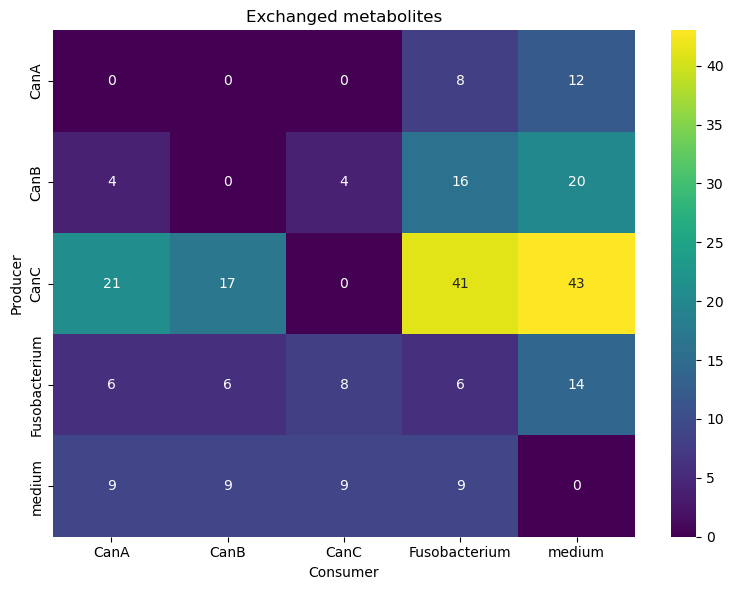

In [69]:
matrix = exchanges_complete.groupby(
    ["compartment_producer", "compartment_consumer"]
).size().unstack(fill_value=0)

plt.figure(figsize=(8,6))
sns.heatmap(matrix, annot=True, fmt="d", cmap="viridis")
plt.title("Exchanged metabolites")
plt.xlabel("Consumer")
plt.ylabel("Producer")
plt.tight_layout()
plt.show()

#### Add magnitude and percentage

In [70]:
exchanges_complete["magnitude"] = exchanges_complete[["flux_producer", "flux_consumer"]].abs().max(axis=1)

In [71]:
exchanges_complete["percentage"] = (
    exchanges_complete["magnitude"] /
    exchanges_complete.groupby("compartment_producer")["magnitude"].transform("sum")
) * 100

In [72]:
exchanges_complete

,metabolite,compartment_producer,flux_producer,compartment_consumer,flux_consumer,magnitude,percentage
1,ac,Fusobacterium,6.299899,medium,NaN,6.299899,10.046101
2,ac,Fusobacterium,6.299899,Fusobacterium,NaN,6.299899,10.046101
3,ac,Fusobacterium,6.299899,medium,NaN,6.299899,10.046101
4,ac_m,medium,3.244527,CanA,NaN,3.244527,8.562973
5,ac_m,medium,3.244527,CanB,NaN,3.244527,8.562973
...,...,...,...,...,...,...,...
258,xylt,CanC,0.000870,Fusobacterium,NaN,0.000870,0.004590
259,xylt,CanC,0.000870,CanA,-0.004033,0.004033,0.021282
260,xylt,CanC,0.000870,Fusobacterium,NaN,0.000870,0.004590
261,xylt,CanC,0.000870,Fusobacterium,NaN,0.000870,0.004590


In [73]:
exchanges_complete.groupby("metabolite")["percentage"].sum().sort_values(ascending=False) #see the percentage distribution

metabolite
co2         106.122118
nh4          70.621671
succ         64.918923
pyr          59.375752
ac_m         34.251891
lac_D        33.432587
ac           30.138302
co2_m        25.225640
nh4_m        24.572840
gly          15.608944
indole        6.147515
gly_m         5.826963
indole_m      5.239944
but           4.487504
but_m         3.825004
sfcys         2.579880
slfcys        2.579880
ppa           1.505517
acac          0.748600
slfcys_m      0.602129
citr_L        0.562094
ppa_m         0.389995
orot          0.361774
aicar         0.267643
atp           0.184716
pe_hs         0.175098
xylt          0.121845
citr_L_m      0.065595
pglyc_hs      0.045836
xmp           0.013800
Name: percentage, dtype: float64

In [74]:
exchanges_complete.to_csv("EXCHANGES_FILES/exchanges_KO_complete.csv") #save the dataframe for vizualizing in ggplot2

In [92]:
exchanges_KO_medium = exchanges_complete[exchanges_complete["compartment_producer"].str.startswith("medium")]

In [90]:
exchanges_KO_medium.to_csv("EXCHANGES_FILES/exchanges_KO_medium.csv")

#### Visualizing exchanges with medium

In [75]:
fluxes = community_exchanges_nz

exchange_fluxes = fluxes[fluxes["reaction"].str.startswith("EX_")]

exchange_fluxes

,compartment,reaction,flux
0,CanA,EX_15dap_e,NaN
1,CanB,EX_15dap_e,NaN
2,CanC,EX_15dap_e,NaN
4,medium,EX_15dap_e,NaN
5,CanA,EX_15dap_m,NaN
...,...,...,...
2455,CanA,EX_zn2_m,NaN
2456,CanB,EX_zn2_m,NaN
2457,CanC,EX_zn2_m,NaN
2458,Fusobacterium,EX_zn2_m,NaN


In [76]:
exchange_total = (
    exchange_fluxes
    .groupby("reaction")["flux"]
    .sum()
    .reset_index()
)

exchange_total

,reaction,flux
0,EX_15dap_e,0.000000
1,EX_15dap_m,0.000000
2,EX_2hb[e],0.000000
3,EX_2hb_e,0.000000
4,EX_2hb_m,0.000000
...,...,...
487,EX_xylt[e],-0.003164
488,EX_xylt_e,-0.003164
489,EX_xylt_m,0.000000
490,EX_zn2_e,-0.000931


In [79]:
initial_medium = pd.DataFrame(
    TyF_KO.medium.items(),
    columns=["reaction", "initial_flux"]
)

initial_medium.head()

,reaction,initial_flux
0,EX_ala_L_m,0.7
1,EX_anth_m,0.7
2,EX_arg_L_m,0.5
3,EX_asn_L_m,0.7
4,EX_asp_L_m,0.7


In [80]:
initial_medium["metabolite"] = initial_medium["reaction"].str.replace("EX_", "")

In [81]:
medium_final = initial_medium.merge(exchange_total, on="reaction", how="outer").fillna(0)

medium_final["final_flux"] = medium_final["initial_flux"] + medium_final["flux"]

medium_final["change"] = medium_final["final_flux"] - medium_final["initial_flux"]

medium_final.sort_values("change", ascending=False).head(20)

,reaction,initial_flux,metabolite,flux,final_flux,change
48,EX_ac_e,0.0,0,6.299899,6.299899,6.299899
155,EX_co2_e,0.0,0,5.248482,5.248482,5.248482
343,EX_nh4_e,0.0,0,4.594315,4.594315,4.594315
49,EX_ac_m,0.0,0,3.244527,3.244527,3.244527
156,EX_co2_m,0.0,0,2.389511,2.389511,2.389511
344,EX_nh4_m,0.0,0,2.327675,2.327675,2.327675
271,EX_h2o[e],0.0,0,2.125612,2.125612,2.125612
154,EX_co2[e],0.0,0,1.084731,1.084731,1.084731
236,EX_gly_e,0.0,0,1.046289,1.046289,1.046289
294,EX_indole_e,0.0,0,0.963775,0.963775,0.963775


In [82]:
medium_final = medium_final[
    medium_final["reaction"].str.endswith("_m")
]
medium_final #filter only the medium reactions

,reaction,initial_flux,metabolite,flux,final_flux,change
1,EX_15dap_m,0.0,0,0.00000,0.00000,0.00000
4,EX_2hb_m,0.0,0,0.00000,0.00000,0.00000
7,EX_2mcit_m,0.0,0,0.00000,0.00000,0.00000
9,EX_2obut_m,0.0,0,0.00000,0.00000,0.00000
13,EX_3aib_D_m,0.0,0,0.00000,0.00000,0.00000
...,...,...,...,...,...,...
480,EX_whhdca_m,0.0,0,0.00000,0.00000,0.00000
483,EX_xmp_m,0.0,0,0.00000,0.00000,0.00000
486,EX_xoltri25_m,0.0,0,0.00000,0.00000,0.00000
489,EX_xylt_m,0.0,0,0.00000,0.00000,0.00000


In [83]:
medium_final["metabolite"] = (
    medium_final["reaction"]
    .str.replace("EX_", "", regex=False)
    .str.replace("_m", "", regex=False)
) #clear the metabolite name

In [84]:
# sort by absolute change
top_metabolites = medium_final.reindex(
    medium_final["change"].abs().sort_values(ascending=False).index
).head(30)

top_metabolites

,reaction,initial_flux,metabolite,flux,final_flux,change
49,EX_ac_m,0.0,ac,3.244527,3.244527,3.244527
156,EX_co2_m,0.0,co2,2.389511,2.389511,2.389511
344,EX_nh4_m,0.0,nh4,2.327675,2.327675,2.327675
444,EX_thr_L_m,0.7,thr_L,-0.700000,0.000000,-0.700000
350,EX_o2_m,0.7,o2,-0.700000,0.000000,-0.700000
273,EX_h2o_m,0.7,h2o,-0.700000,0.000000,-0.700000
112,EX_asp_L_m,0.7,asp_L,-0.700000,0.000000,-0.700000
411,EX_ser_L_m,0.7,ser_L,-0.700000,0.000000,-0.700000
237,EX_gly_m,0.7,gly,0.551962,1.251962,0.551962
452,EX_trp_L_m,0.5,trp_L,-0.500000,0.000000,-0.500000


In [85]:
heatmap_data = top_metabolites.set_index("metabolite")[["initial_flux", "final_flux"]]

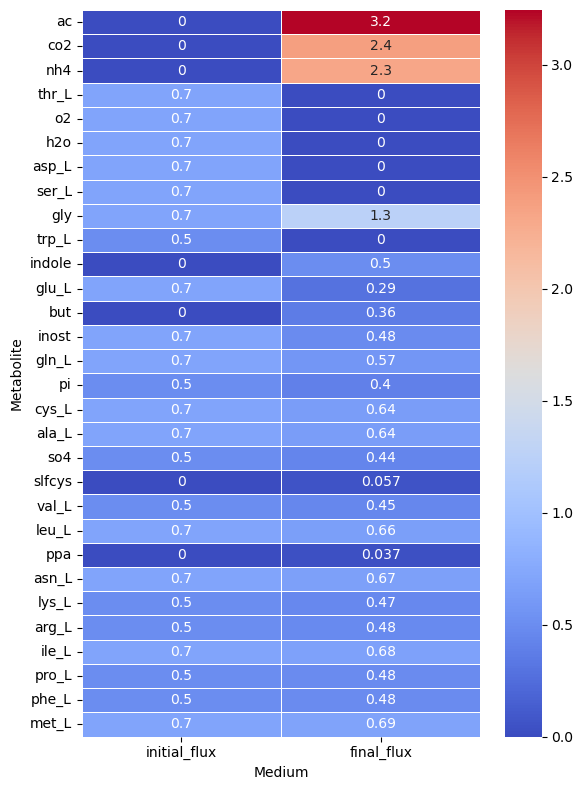

In [86]:
plt.figure(figsize=(6,8))

sns.heatmap(
    heatmap_data,
    cmap="coolwarm",
    annot=True,
    linewidths=0.5
)
plt.ylabel("Metabolite")
plt.xlabel("Medium")
plt.tight_layout()
plt.show()

In [51]:
Tumor.reactions.EX_gal_e__CanA

Reaction identifier,EX_gal_e__CanA
Name,EX_gal_e
Memory address,0x7f9cead55390
Stoichiometry,gal[e]__CanA <=> 0.10374853987469469 gal_m gal[e] <=> 0.10374853987469469 gal[e]
GPR,
Lower bound,-100
Upper bound,10.0
